## Лабораторная работа 1. Иерархический кластерный анализ

**Курс:** Анализ данных на Python

**Студент:** Муравья Никита

**Задача:** «Economics of Cities»

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram, cophenet
from scipy.spatial.distance import pdist

sns.set(style="whitegrid", palette="Set2")
RANDOM_STATE = 42  

---
### Данные

Экономические условия в 48 городах мира в 1991 году (отдел экономических исследований банка Union, Швейцария):

| Признак | Смысл | Единицы |
|---|---|---|
| `Work` | взвешенное среднее числа рабочих часов в год по 12 профессиям | часы |
| `Price` | индекс цен 112 товаров и услуг, включая аренду жилья | Цюрих $= 100$ |
| `Salary` | индекс зарплаты за час работы по 12 профессиям после налогов | Цюрих $= 100$ |

Каждый город будем считать точкой $x_i = (\text{Work}_i, \text{Price}_i, \text{Salary}_i) \in \mathbb{R}^3$. Пропуски в файле закодированы числом $-9999$.

In [2]:
df_raw = pd.read_csv("Econom_Cities_data.csv", sep=";", decimal=",", index_col="City")
df_raw = df_raw.replace(-9999, np.nan)
df_raw[df_raw.isna().any(axis=1)]

,Work,Price,Salary
City,,,
Cairo,NaN,37.1,NaN
Jakarta,NaN,43.6,NaN


У Каира и Джакарты нет двух признаков из трёх. Заполнить их средним означало бы придумать городу две трети профиля, поэтому исключаем эти города, остаётся 46.

In [3]:
df_raw.dropna().describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Work,46.0,1879.91,174.34,1583.0,1745.25,1849.00,1976.25,2375.0
Price,46.0,70.10,21.39,30.3,51.78,70.95,81.90,115.5
Salary,46.0,39.55,24.76,2.7,14.38,43.65,59.70,100.0


Стандартное отклонение `Work` около 174 часов, у индексов 21–25 пунктов. Без масштабирования вклад `Work` в евклидово расстояние $\rho^2$ был бы в 50–70 раз больше, и кластеры строились бы по одному признаку. Поэтому стандартизуем: $z_{ij} = (x_{ij} - \bar{x}_j) / s_j$.

In [4]:
df = df_raw.dropna()
names = df.index.str.replace("_", " ")
scaler = StandardScaler()
X = scaler.fit_transform(df)
xy_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)  # только для рисунков

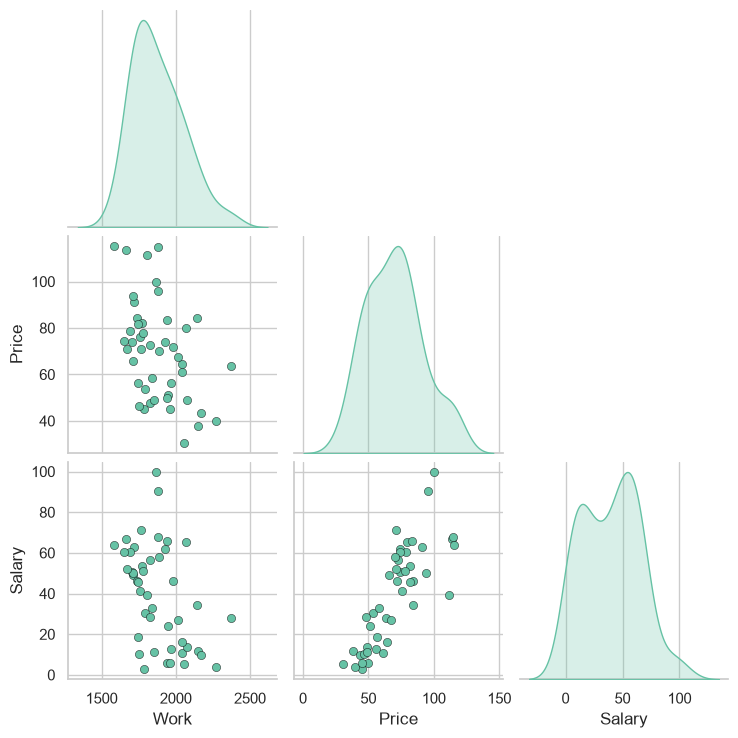

,Work,Price,Salary
Work,1.00,-0.45,-0.46
Price,-0.45,1.00,0.80
Salary,-0.46,0.80,1.00


In [5]:
g = sns.pairplot(df, diag_kind="kde", corner=True, plot_kws={"s": 35, "edgecolor": "k", "linewidth": 0.3})
plt.show()
df.corr().round(2)

`Price` и `Salary` сильно связаны ($r \approx 0{,}80$): где дорого, там и платят больше, иначе там бы никто не жил :) С обоими признаками `Work` связан отрицательно ($r \approx -0{,}45$), в богатых городах работают меньше.

---
### Функции

In [6]:
def plot_clusters(xy, labels, title, xlabel, ylabel, annotate=True):
    """Рисует точки xy (n x 2) с раскраской по кластерам.

    labels   -- метки кластеров, шум DBSCAN (-1) рисуется серыми крестиками;
    annotate -- подписывать ли города (их 46, подписи читаются).
    """
    fig, ax = plt.subplots(figsize=(9, 6))
    for k in np.unique(labels):
        mask = labels == k
        if k == -1:
            ax.scatter(*xy[mask].T, c="grey", marker="x", s=60, label="шум")
        else:
            ax.scatter(*xy[mask].T, s=60, edgecolor="k", linewidth=0.5, label=f"кластер {k}")
    if annotate:
        for (x, y), name in zip(xy, names):
            ax.annotate(name, (x, y), xytext=(3, 3), textcoords="offset points", fontsize=7)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.legend()
    plt.show()

In [7]:
def relabel(labels, by="Salary"):
    """Перенумеровывает кластеры 0, 1, ... по возрастанию среднего признака `by`.

    Номера кластеров у разных методов случайны, а так кластер 0 всегда самый
    низкооплачиваемый и разные методы удобно сравнивать. Шум (-1) не трогаем.
    """
    labels = np.asarray(labels)
    order = df[by].groupby(labels).mean().drop(-1, errors="ignore").sort_values().index
    mapping = {old: new for new, old in enumerate(order)} | {-1: -1}
    return np.array([mapping[label] for label in labels])

In [8]:
def plot_dendrogram(Z, k=None):
    """Дендрограмма с подписями городов.

    k -- если задано, проводим линию отсечения посередине между высотами слияний,
         после которых остаётся k и k - 1 кластеров, и красим ветви по кластерам.
    """
    cut = (Z[-k, 2] + Z[-k + 1, 2]) / 2 if k else None
    plt.figure(figsize=(14, 6))
    dendrogram(Z, labels=names.tolist(), leaf_rotation=90, leaf_font_size=9,
               color_threshold=cut, above_threshold_color="grey")
    if cut:
        plt.axhline(cut, ls="--", color="red", label=f"отсечение: k = {k}")
        plt.legend()
    plt.title("Дендрограмма (Ward)" + (f", k = {k}" if k else ""))
    plt.ylabel("высота слияния")
    plt.show()

---
### Иерархический кластерный анализ

**1. Способ связи.** Агломеративная процедура стартует с $n$ одиночных кластеров и на каждом шаге сливает два ближайших. Расстояние между кластерами $A$ и $B$:

* single: $\min_{a \in A, b \in B} \rho(a, b)$;
* complete: $\max \rho(a, b)$;
* average: $\frac{1}{|A||B|} \sum_{a, b} \rho(a, b)$;
* Ward: прирост внутрикластерной суммы квадратов $\Delta(A, B) = \frac{|A||B|}{|A| + |B|} \|\bar{a} - \bar{b}\|^2$.

Для каждого способа посчитаем кофенетическую корреляцию (согласие расстояний «по дереву» с исходными) и размеры кластеров при разрезе на 4 группы.

In [9]:
distances = pdist(X)
rows = []
for method in ["single", "complete", "average", "ward"]:
    Z_method = linkage(X, method)
    sizes = np.bincount(fcluster(Z_method, 4, criterion="maxclust"))[1:]
    rows.append({"method": method, "cophenetic_corr": cophenet(Z_method, distances)[0],
                 "sizes_k4": sorted(sizes.tolist(), reverse=True)})
pd.DataFrame(rows).round(3)

,method,cophenetic_corr,sizes_k4
0,single,0.634,"[42, 2, 1, 1]"
1,complete,0.719,"[19, 11, 10, 6]"
2,average,0.741,"[19, 19, 6, 2]"
3,ward,0.703,"[19, 14, 7, 6]"


Single linkage выдаёт цепочку $[42, 2, 1, 1]$, average отщепляет кластер из двух городов. Complete и Ward дают нормальные группы. Берём **метод Уорда**: он минимизирует ту же сумму квадратов, что и k-means, и работы 1 и 2 можно будет сравнить напрямую. Кофенетическая корреляция у всех методов близка (0,63–0,74), и качество разбиения она не оценивает.

**2. Дендрограмма.**

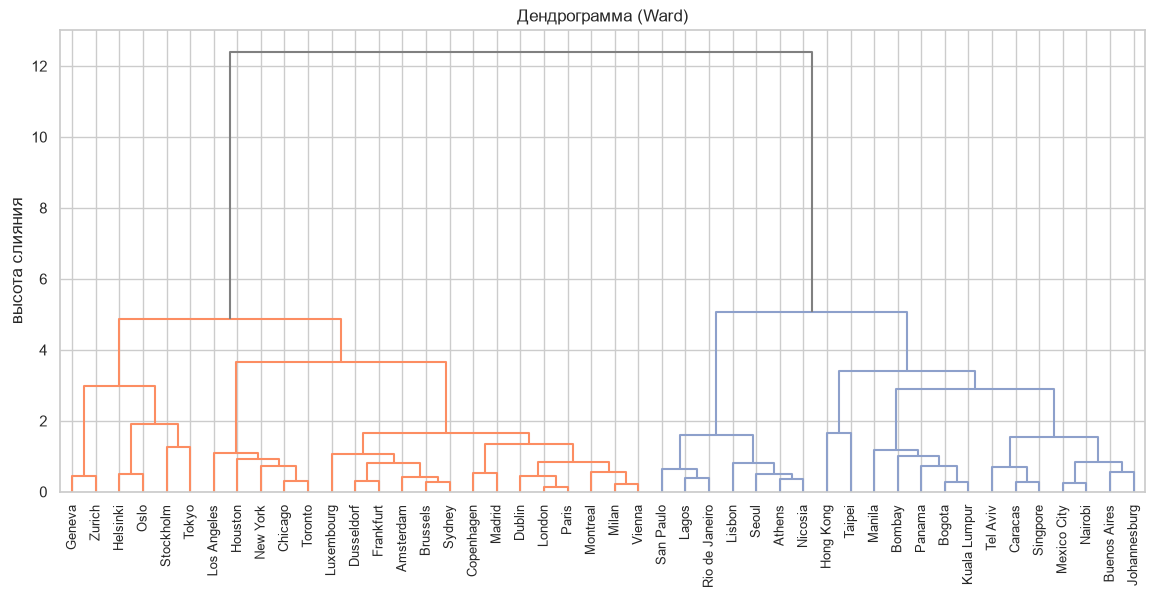

In [10]:
Z = linkage(X, method="ward")
plot_dendrogram(Z)

**3. Число кластеров.** Дерево режут перед слиянием, которое происходит заметно выше предыдущих. В строке $k$ таблицы стоит слияние, после которого остаётся $k$ кластеров.

In [11]:
heights = pd.DataFrame({"k": np.arange(1, 11), "height": Z[::-1, 2][:10]})
heights["jump"] = heights.height - heights.height.shift(-1)
heights.round(2)

,k,height,jump
0,1,12.40,7.34
1,2,5.06,0.20
2,3,4.86,1.20
3,4,3.66,0.26
4,5,3.40,0.41
5,6,2.99,0.08
6,7,2.91,1.00
7,8,1.91,0.24
8,9,1.67,0.02
9,10,1.65,NaN


Самый большой скачок ($5{,}06 \to 12{,}40$) указывает на $k = 2$, второй ($3{,}66 \to 4{,}86$) на $k = 4$. Переход от трёх кластеров к двум почти ничего не стоит ($4{,}86 \to 5{,}06$), так что разрез на 3 неустойчив. Посмотрим на индексы качества.

In [12]:
rows = []
for k in range(2, 9):
    labels = fcluster(Z, k, criterion="maxclust")
    rows.append({"k": k, "silhouette": silhouette_score(X, labels),
                 "calinski_harabasz": calinski_harabasz_score(X, labels),
                 "davies_bouldin": davies_bouldin_score(X, labels)})
pd.DataFrame(rows).round(3)

,k,silhouette,calinski_harabasz,davies_bouldin
0,2,0.470,55.351,0.808
1,3,0.361,39.917,0.818
2,4,0.355,38.930,1.002
3,5,0.348,37.209,0.905
4,6,0.366,37.964,0.889
5,7,0.396,39.411,0.778
6,8,0.399,43.532,0.774


Силуэт и индекс Калински–Харабаша максимальны при $k = 2$, индекс Дэвиса–Боулдина (меньше лучше) при $k = 7$–$8$. Разбиение на два кластера делит города на богатые и небогатые, это видно на диаграмме `Price`–`Salary` и без анализа. Выбираем **$k = 4$**: это второй по величине скачок дендрограммы, а силуэт ($0{,}355$) почти не отличается от соседних $k = 3$ и $k = 5$.

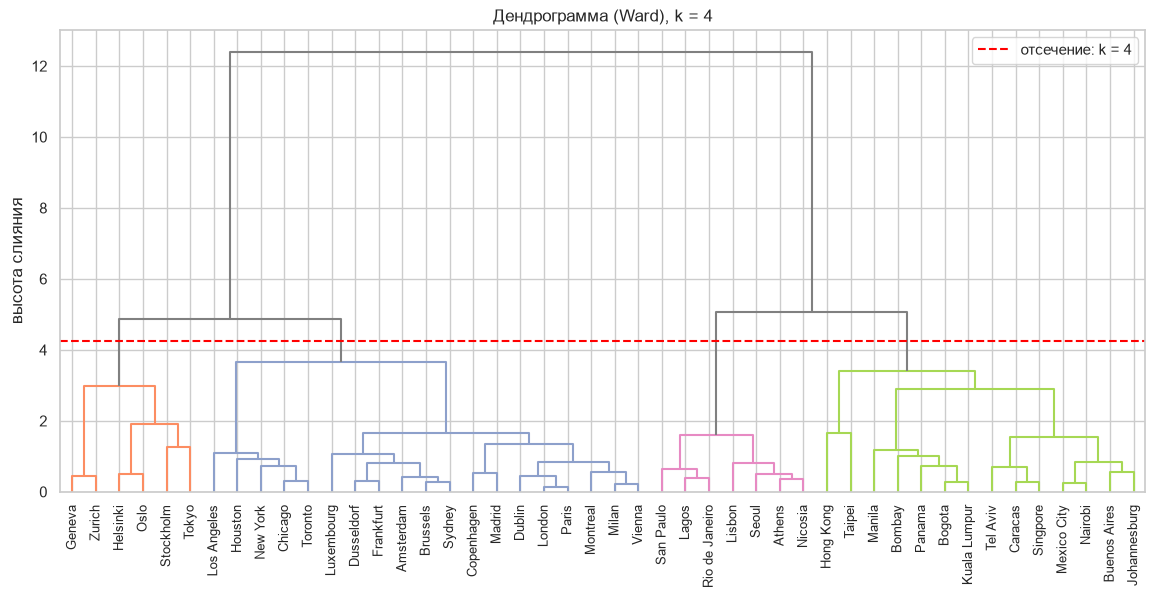

In [13]:
K = 4
labels_hier = relabel(fcluster(Z, K, criterion="maxclust"))
plot_dendrogram(Z, k=K)

Силуэт по объектам: $s(i) < 0$ означает, что город ближе к соседнему кластеру, чем к своему.

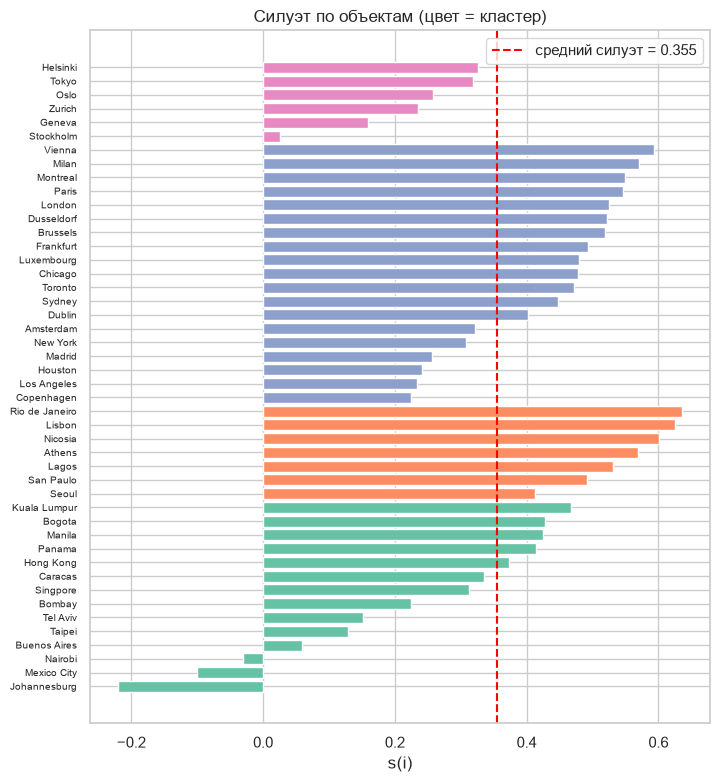

City
Johannesburg   -0.220
Mexico_City    -0.101
Nairobi        -0.031
dtype: float64

In [14]:
silhouettes = pd.Series(silhouette_samples(X, labels_hier), index=df.index)
fig, ax = plt.subplots(figsize=(8, 9))
order = np.lexsort((silhouettes.values, labels_hier))
ax.barh(np.arange(len(order)), silhouettes.values[order],
        color=[sns.color_palette()[label] for label in labels_hier[order]])
ax.set_yticks(np.arange(len(order)), names[order], fontsize=7)
ax.axvline(silhouettes.mean(), ls="--", color="red", label=f"средний силуэт = {silhouettes.mean():.3f}")
ax.set(title="Силуэт по объектам (цвет = кластер)", xlabel="s(i)")
ax.legend()
plt.show()
silhouettes[silhouettes < 0].round(3)

Отрицательный силуэт у Йоханнесбурга, Мехико и Найроби из кластера 0. Ward жадный и не пересматривает слияния, сделанные на ранних шагах.

**4. Профили кластеров.** Кластеры пронумерованы по возрастанию средней зарплаты. `Salary_to_Price` показывает, какую долю цюрихской корзины покупает час работы.

In [15]:
profile = df.assign(Salary_to_Price=df.Salary / df.Price).groupby(labels_hier).mean().round(2)
profile.insert(0, "size", pd.Series(labels_hier).value_counts().sort_index().values)
profile["cities"] = df.index.to_series().groupby(labels_hier).agg(", ".join)
profile

,size,Work,Price,Salary,Salary_to_Price,cities
0,14,2082.36,53.12,14.91,0.26,"Bogota, Bombay, Buenos_Aires, Caracas, Hong_Ko..."
1,7,1798.86,50.94,19.21,0.37,"Athens, Lagos, Lisbon, Nicosia, Rio_de_Janeiro..."
2,19,1792.00,77.53,55.16,0.72,"Amsterdam, Brussels, Chicago, Copenhagen, Dubl..."
3,6,1780.50,108.55,71.30,0.67,"Geneva, Helsinki, Oslo, Stockholm, Tokyo, Zurich"


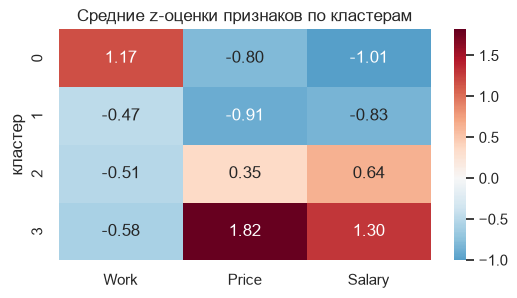

In [16]:
fig, ax = plt.subplots(figsize=(6, 3))
sns.heatmap(pd.DataFrame(X, columns=df.columns).groupby(labels_hier).mean(),
            annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set(title="Средние z-оценки признаков по кластерам", ylabel="кластер")
plt.show()

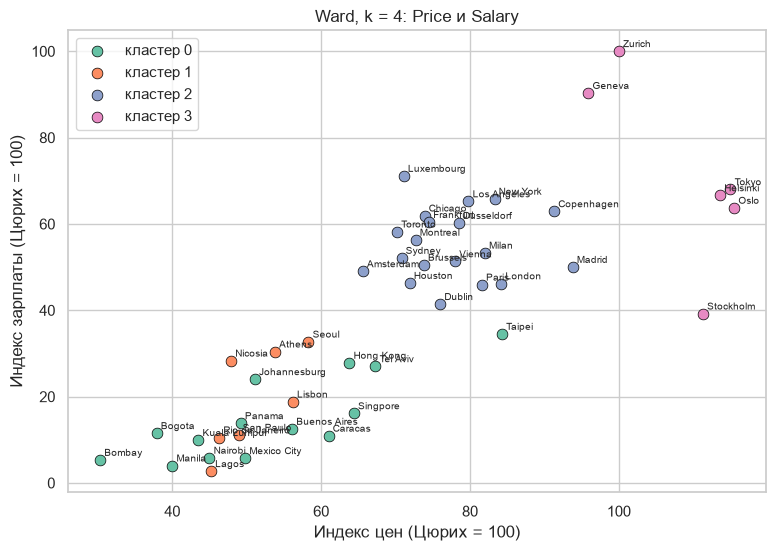

In [17]:
plot_clusters(df[["Price", "Salary"]].values, labels_hier, "Ward, k = 4: Price и Salary",
              "Индекс цен (Цюрих = 100)", "Индекс зарплаты (Цюрих = 100)")

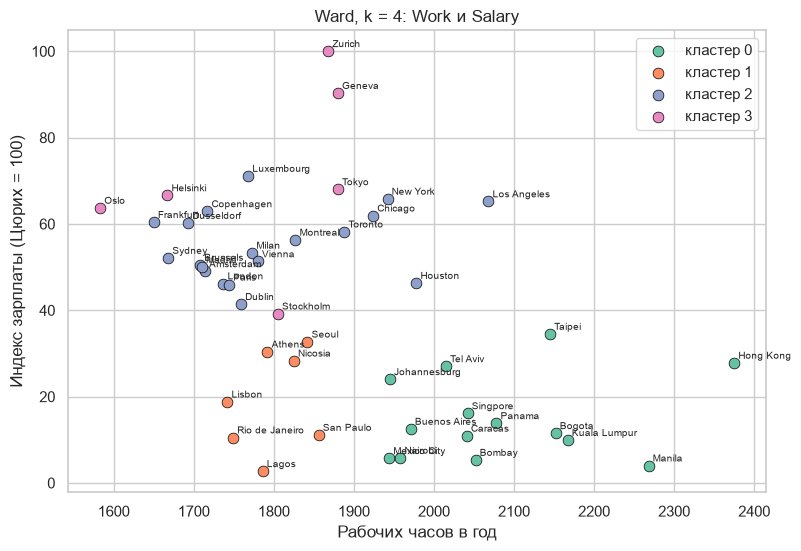

In [18]:
plot_clusters(df[["Work", "Salary"]].values, labels_hier, "Ward, k = 4: Work и Salary",
              "Рабочих часов в год", "Индекс зарплаты (Цюрих = 100)")

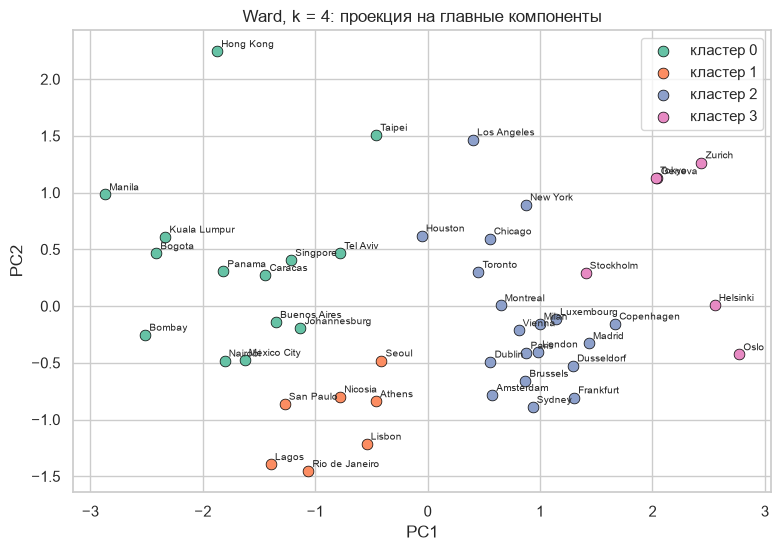

In [19]:
plot_clusters(xy_pca, labels_hier, "Ward, k = 4: проекция на главные компоненты", "PC1", "PC2")

Тепловая карта z-оценок всех городов. Строки упорядочены по дендрограмме Уорда, полоса слева показывает кластер. Видно, какой признак отличает каждую группу: у кластера 0 красный `Work`, у кластера 3 красные `Price` и `Salary`.

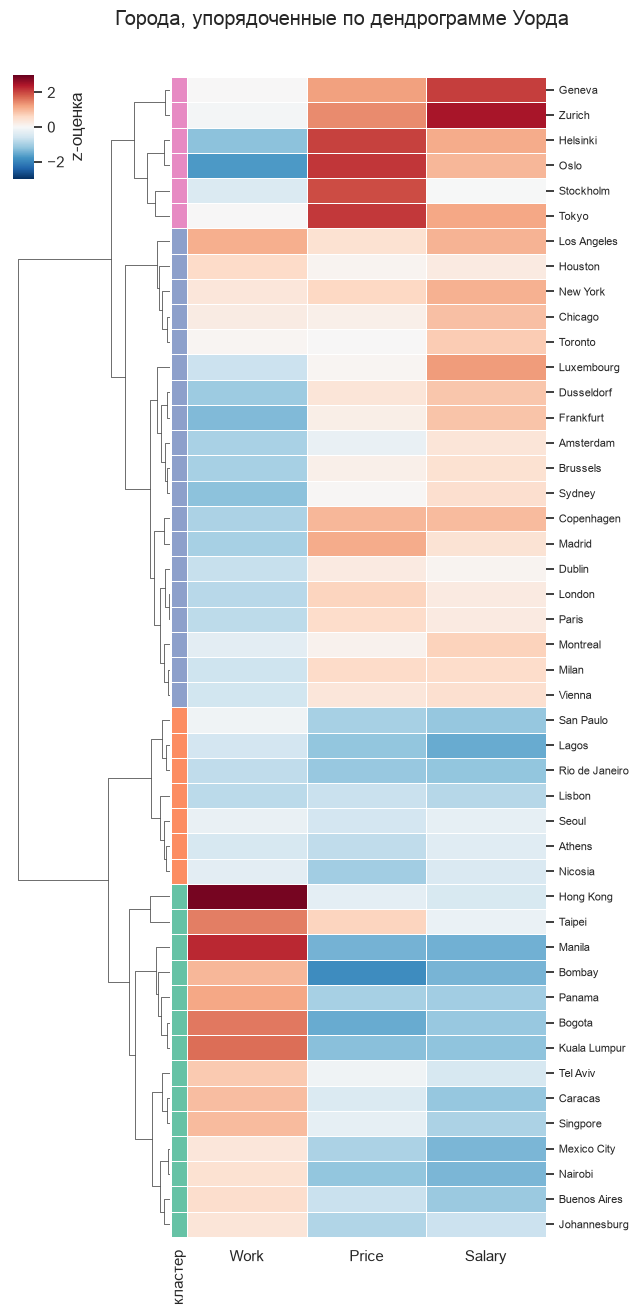

In [20]:
row_colors = pd.Series(labels_hier, index=names).map(dict(enumerate(sns.color_palette()))).rename("кластер")
g = sns.clustermap(pd.DataFrame(X, index=names, columns=df.columns), row_linkage=Z, col_cluster=False,
                   row_colors=row_colors, cmap="RdBu_r", center=0, vmin=-3, vmax=3, yticklabels=True,
                   linewidths=0.5, linecolor="white", figsize=(7, 13), dendrogram_ratio=(0.3, 0.03),
                   cbar_pos=(0.03, 0.88, 0.03, 0.08), cbar_kws={"label": "z-оценка"})
g.ax_heatmap.tick_params(axis="y", labelsize=8)
g.ax_heatmap.set(xlabel="", ylabel="")
g.fig.suptitle("Города, упорядоченные по дендрограмме Уорда", y=1.01)
plt.show()

---
### Интерпретация

| № | Название | Размер | Work, ч | Price | Salary | Salary/Price |
|---|---|---|---|---|---|---|
| 0 | «Работают много, получают мало» | 14 | **2082** | 53 | **15** | 0,26 |
| 1 | «Дешёвая периферия» | 7 | 1799 | **51** | 19 | 0,37 |
| 2 | «Благополучный Запад» | 19 | 1792 | 78 | 55 | **0,72** |
| 3 | «Дорого и богато» | 6 | 1781 | **109** | **71** | 0,67 |

**Кластер 0:** Богота, Бомбей, Буэнос-Айрес, Каракас, Гонконг, Йоханнесбург, Куала-Лумпур, Манила, Мехико, Найроби, Панама, Сингапур, Тайбэй, Тель-Авив. Развивающиеся мегаполисы с самым длинным рабочим годом и худшей покупательной способностью. Сюда попали и «азиатские тигры» 1991 года (Гонконг, Сингапур, Тайбэй): экономика уже растёт, а платят пока скромно.

**Кластер 1:** Афины, Лагос, Лиссабон, Никосия, Рио-де-Жанейро, Сан-Паулу, Сеул. Бедные города с обычной продолжительностью работы. От кластера 0 отличаются прежде всего признаком `Work`, а география пёстрая: кластеризация группирует по экономике, карты она не видит.

**Кластер 2:** Амстердам, Брюссель, Чикаго, Копенгаген, Дублин, Дюссельдорф, Франкфурт, Хьюстон, Лондон, Лос-Анджелес, Люксембург, Мадрид, Милан, Монреаль, Нью-Йорк, Париж, Сидней, Торонто, Вена. Развитые города Западной Европы, Северной Америки и Австралии с лучшей покупательной способностью.

**Кластер 3:** Женева, Хельсинки, Осло, Стокгольм, Токио, Цюрих. Самые дорогие и самые высокооплачиваемые города. Покупательная способность здесь ниже, чем у кластера 2, высокие зарплаты съедаются ценами (в Стокгольме отношение и вовсе $0{,}35$).

Ось $\text{Price} + \text{Salary}$ отделяет кластеры $\{0, 1\}$ от $\{2, 3\}$, внутри «бедной» половины группы различает `Work`, внутри «богатой» уровень цен. Значит, разрез на 2 кластера должен вкладываться в разрез на 4:

In [21]:
pd.crosstab(pd.Series(relabel(fcluster(Z, 2, criterion="maxclust")), name="k = 2"),
            pd.Series(labels_hier, name="k = 4"))

k = 4,0,1,2,3
k = 2,,,,
0,14,7,0,0
1,0,0,19,6


Так и есть, на то иерархия и иерархия :)

---
### Выводы

1. Для 46 городов выбран метод Уорда и $k = 4$.
2. Получились четыре типа городов: «работают много, получают мало», «дешёвая периферия», «благополучный Запад», «дорого и богато».
3. Самая высокая покупательная способность не у самых богатых городов, а у «среднего» Запада.
4. Граница между кластерами 0 и 1 размыта: у трёх городов кластера 0 отрицательный силуэт.